<a href="https://colab.research.google.com/github/Aayushka05/human-activity-recognition-m/blob/main/HAR_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human Activity Recognition Using Sensor Data
**Dataset:** UCI HAR (smartphone accelerometer + gyroscope, 30 volunteers, 6 activities)
**Activities:** Walking, Walking Upstairs, Walking Downstairs, Sitting, Standing, Laying

**Pipeline:** Load data -> Explore -> Scale -> Train classical ML models -> Compare -> Evaluate best model -> Deep learning (1D-CNN on raw signals) -> Save model

## 1. Imports

In [ ]:
import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)

## 2. Download and extract the dataset

In [ ]:
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
if not os.path.exists("UCI HAR Dataset"):
    urllib.request.urlretrieve(URL, "har.zip")
    with zipfile.ZipFile("har.zip") as z:
        z.extractall(".")
    # The outer zip contains a second zip with the actual data
    if os.path.exists("UCI HAR Dataset.zip"):
        with zipfile.ZipFile("UCI HAR Dataset.zip") as z:
            z.extractall(".")
print(os.listdir("UCI HAR Dataset"))

['train', 'features_info.txt', 'activity_labels.txt', '.DS_Store', 'test', 'features.txt', 'README.txt']


## 3. Load the data (561 pre-engineered features)

In [ ]:
BASE = "UCI HAR Dataset"

features = pd.read_csv(f"{BASE}/features.txt", sep=r"\s+", header=None, names=["id", "name"])["name"].tolist()
activity_labels = pd.read_csv(f"{BASE}/activity_labels.txt", sep=r"\s+", header=None, names=["id", "activity"])
class_names = activity_labels["activity"].tolist()

X_train = pd.read_csv(f"{BASE}/train/X_train.txt", sep=r"\s+", header=None).values
y_train = pd.read_csv(f"{BASE}/train/y_train.txt", header=None).values.ravel() - 1   # 0..5
X_test  = pd.read_csv(f"{BASE}/test/X_test.txt",  sep=r"\s+", header=None).values
y_test  = pd.read_csv(f"{BASE}/test/y_test.txt",  header=None).values.ravel() - 1

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Classes:", class_names)

Train: (7352, 561) | Test: (2947, 561)
Classes: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


## 4. Exploratory data analysis

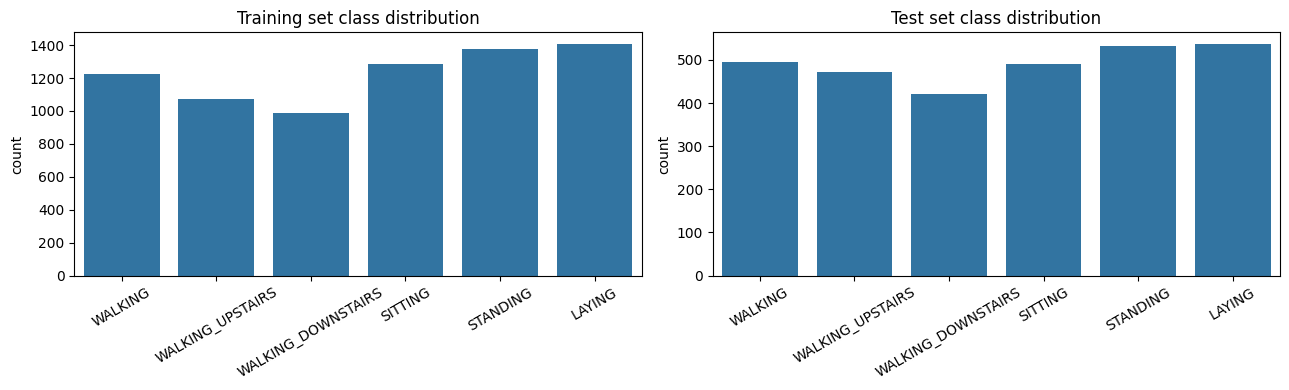

Missing values in train: 0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=[class_names[i] for i in y_train], ax=ax[0], order=class_names)
ax[0].set_title("Training set class distribution"); ax[0].tick_params(axis="x", rotation=30)
sns.countplot(x=[class_names[i] for i in y_test], ax=ax[1], order=class_names)
ax[1].set_title("Test set class distribution"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print("Missing values in train:", np.isnan(X_train).sum())

### Raw sensor signal examples (one window per activity)

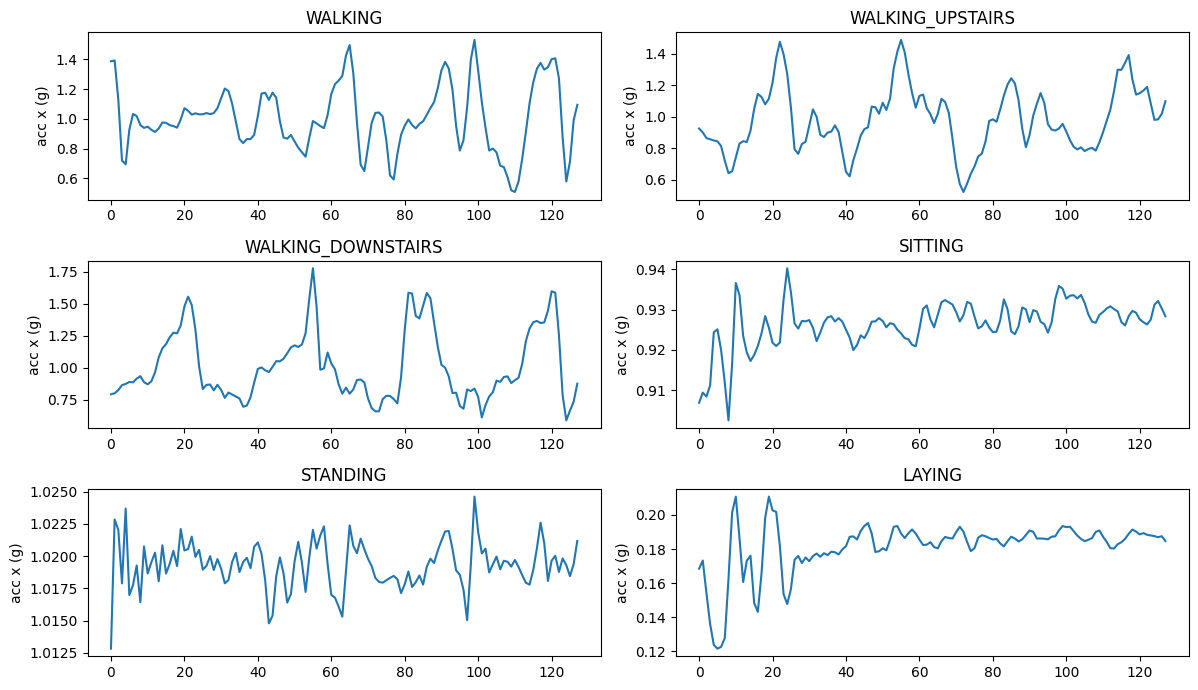

In [ ]:
def load_signal(name, split):
    return pd.read_csv(f"{BASE}/{split}/Inertial Signals/{name}_{split}.txt", sep=r"\s+", header=None).values

acc_x = load_signal("total_acc_x", "train")
plt.figure(figsize=(12, 7))
for i, act in enumerate(class_names):
    idx = np.where(y_train == i)[0][0]
    plt.subplot(3, 2, i + 1)
    plt.plot(acc_x[idx])
    plt.title(act); plt.ylabel("acc x (g)")
plt.tight_layout(); plt.show()

## 5. Feature scaling

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

## 6. Train and compare classical ML models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           SVC(kernel="rbf", C=10, gamma="scale"),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

results, trained = [], {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    acc = accuracy_score(y_test, pred)
    results.append({"Model": name, "Test Accuracy": round(acc, 4), "Time (s)": round(time.time() - t0, 1)})
    trained[name] = model
    print(f"{name:22s} accuracy = {acc:.4f}")

results_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
results_df

Logistic Regression    accuracy = 0.9549
KNN (k=5)              accuracy = 0.8802
SVM (RBF)              accuracy = 0.9549
Random Forest          accuracy = 0.9291


,Model,Test Accuracy,Time (s)
0,Logistic Regression,0.9549,13.2
1,SVM (RBF),0.9549,5.4
2,Random Forest,0.9291,30.9
3,KNN (k=5),0.8802,2.1


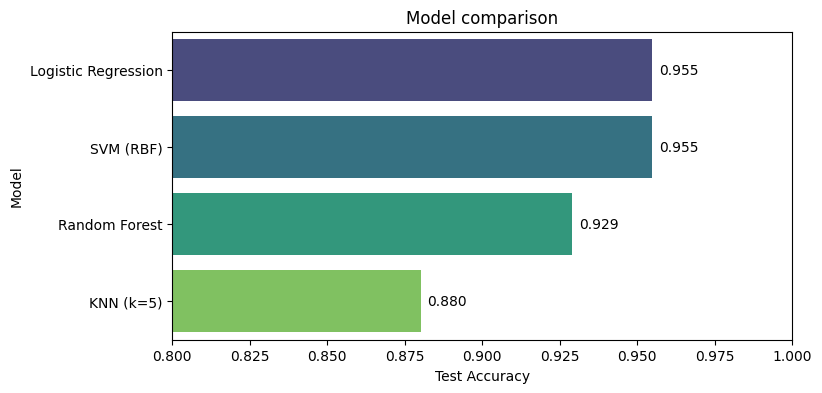

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="Test Accuracy", y="Model", palette="viridis")
plt.xlim(0.8, 1.0); plt.title("Model comparison")
for i, v in enumerate(results_df["Test Accuracy"]):
    plt.text(v + 0.002, i, f"{v:.3f}", va="center")
plt.show()

## 7. Detailed evaluation of the best model

Best model: Logistic Regression
                    precision    recall  f1-score   support

           WALKING       0.94      0.99      0.97       496
  WALKING_UPSTAIRS       0.96      0.95      0.95       471
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.97      0.93       532
            LAYING       1.00      0.99      0.99       537

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



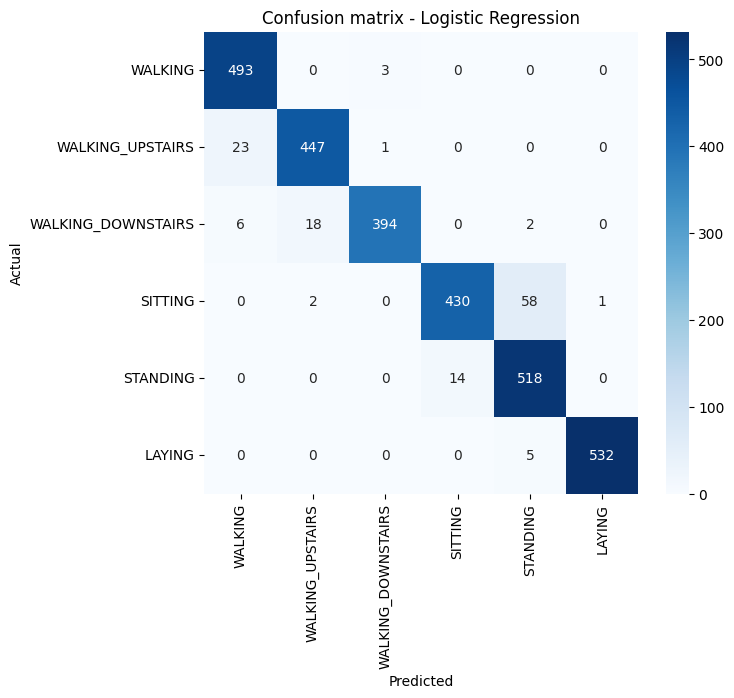

In [ ]:
best_name = results_df.loc[0, "Model"]
best_model = trained[best_name]
y_pred = best_model.predict(X_test_s)
print("Best model:", best_name)
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix - {best_name}")
plt.show()

## 8. Feature importance (Random Forest)

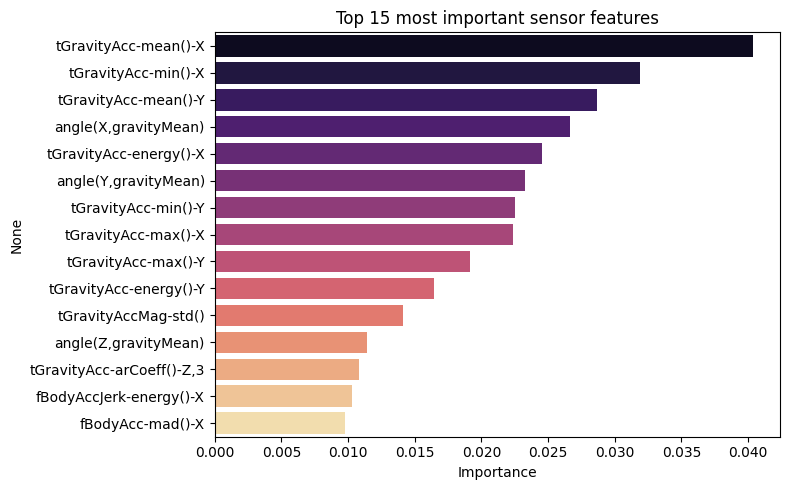

In [ ]:
rf = trained["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, palette="magma")
plt.title("Top 15 most important sensor features"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()

## 9. Deep learning: 1D-CNN on raw sensor signals
Instead of the 561 hand-crafted features, the CNN learns directly from the 9 raw channels
(body acc xyz, body gyro xyz, total acc xyz), each window = 128 time steps (2.56 s at 50 Hz).

In [ ]:
signals = ["body_acc_x", "body_acc_y", "body_acc_z",
           "body_gyro_x", "body_gyro_y", "body_gyro_z",
           "total_acc_x", "total_acc_y", "total_acc_z"]

def load_raw(split):
    return np.dstack([load_signal(s, split) for s in signals])   # (samples, 128, 9)

Xr_train, Xr_test = load_raw("train"), load_raw("test")
print("Raw train:", Xr_train.shape, "| Raw test:", Xr_test.shape)

Raw train: (7352, 128, 9) | Raw test: (2947, 128, 9)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models as kmodels
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

cnn = kmodels.Sequential([
    layers.Input(shape=(128, 9)),
    layers.Conv1D(64, 5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),
    layers.Conv1D(128, 5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),
    layers.Conv1D(128, 3, activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 124, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 58, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 58, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 29, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 27, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,726 (401.27 KB)

 Trainable params: 102,342 (399.77 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/30
98/98 - 9s - 92ms/step - accuracy: 0.8728 - loss: 0.3351 - val_accuracy: 0.1768 - val_loss: 2.0547
Epoch 2/30
98/98 - 9s - 91ms/step - accuracy: 0.9558 - loss: 0.1095 - val_accuracy: 0.3681 - val_loss: 2.3301
Epoch 3/30
98/98 - 7s - 71ms/step - accuracy: 0.9586 - loss: 0.0978 - val_accuracy: 0.5141 - val_loss: 1.2650
Epoch 4/30
98/98 - 10s - 105ms/step - accuracy: 0.9618 - loss: 0.0904 - val_accuracy: 0.8577 - val_loss: 0.3660
Epoch 5/30
98/98 - 9s - 91ms/step - accuracy: 0.9582 - loss: 0.0922 - val_accuracy: 0.8821 - val_loss: 0.4567
Epoch 6/30
98/98 - 10s - 103ms/step - accuracy: 0.9614 - loss: 0.0853 - val_accuracy: 0.8976 - val_loss: 0.4087
Epoch 7/30
98/98 - 8s - 81ms/step - accuracy: 0.9622 - loss: 0.0784 - val_accuracy: 0.8631 - val_loss: 0.5016
Epoch 8/30
98/98 - 5s - 56ms/step - accuracy: 0.9629 - loss: 0.0772 - val_accuracy: 0.8622 - val_loss: 0.5568
Epoch 9/30
98/98 - 11s - 110ms/step - accuracy: 0.9626 - loss: 0.0764 - val_accuracy: 0.8631 - val_loss: 0.5513


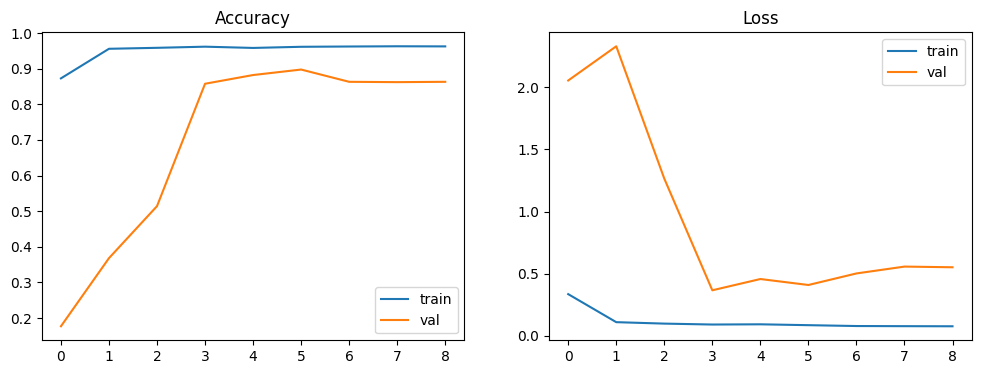

In [ ]:
history = cnn.fit(
    Xr_train, y_train,
    validation_split=0.15,
    epochs=30, batch_size=64,
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=2,
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

1D-CNN test accuracy: 0.8599
                    precision    recall  f1-score   support

           WALKING       0.97      0.83      0.90       496
  WALKING_UPSTAIRS       0.93      0.95      0.94       471
WALKING_DOWNSTAIRS       1.00      0.75      0.86       420
           SITTING       0.62      0.91      0.74       491
          STANDING       0.80      0.70      0.75       532
            LAYING       0.99      1.00      0.99       537

          accuracy                           0.86      2947
         macro avg       0.89      0.86      0.86      2947
      weighted avg       0.88      0.86      0.86      2947



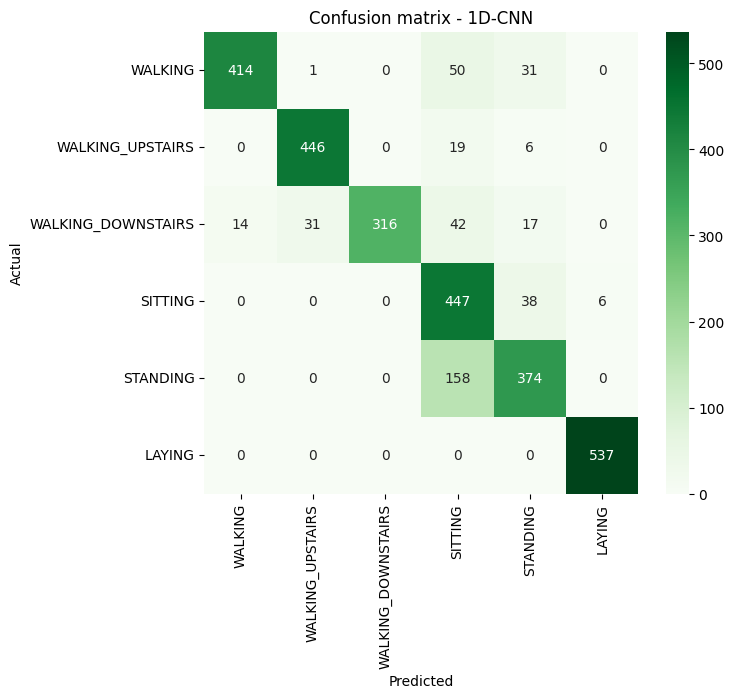

In [ ]:
test_loss, test_acc = cnn.evaluate(Xr_test, y_test, verbose=0)
print(f"1D-CNN test accuracy: {test_acc:.4f}")

y_pred_cnn = np.argmax(cnn.predict(Xr_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred_cnn, target_names=class_names))

cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix - 1D-CNN")
plt.show()

## 10. Final comparison, save model, and sample prediction

In [ ]:
final = pd.concat([results_df[["Model", "Test Accuracy"]],
                   pd.DataFrame([{"Model": "1D-CNN (raw signals)", "Test Accuracy": round(test_acc, 4)}])]
                 ).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
display(final)

import joblib
joblib.dump({"model": best_model, "scaler": scaler, "classes": class_names}, "har_best_model.pkl")
cnn.save("har_cnn.keras")

# Predict a random test window
i = np.random.randint(len(X_test))
pred = best_model.predict(scaler.transform(X_test[i:i+1]))[0]
print(f"Sample {i}: actual = {class_names[y_test[i]]}, predicted = {class_names[pred]}")

,Model,Test Accuracy
0,Logistic Regression,0.9549
1,SVM (RBF),0.9549
2,Random Forest,0.9291
3,KNN (k=5),0.8802
4,1D-CNN (raw signals),0.8599


Sample 1238: actual = SITTING, predicted = SITTING


## 11. Conclusion
- Classical models on engineered features reach roughly 90-96% accuracy; the 1D-CNN on raw signals is competitive without manual feature engineering.
- Most confusion is between **Sitting vs Standing** (similar posture, little motion) and between the three walking types.
- Dynamic activities are separated easily; static ones are harder.

**Future work:** LSTM / CNN-LSTM hybrids, subject-wise cross-validation, hyperparameter tuning, deployment on a microcontroller (TinyML) using a quantized model.